# Introduction to Neural Networks

## Project Overview

This project focuses on understanding the fundamental concepts of neural networks and implementing a neural network model using a real-world dataset from Kaggle.

The project will begin with the basic building blocks of a neural network, including inputs, weights, bias, activation functions, and outputs. A single neuron and a small neural network layer will be implemented from scratch using NumPy, followed by visualizations of the ReLU and Sigmoid activation functions.

After completing the fundamentals, the concepts will be applied to the Diabetes 130-US Hospitals dataset to develop and evaluate a neural network model for readmission classification.

The trained model will then be integrated into a Streamlit application to demonstrate an end-to-end machine learning workflow.

## Objectives

- Understand the architecture and working principles of neural networks.
- Implement a single neuron and a small layer using NumPy.
- Visualize ReLU and Sigmoid activation functions.
- Prepare and analyze a real-world dataset.
- Train and evaluate a neural network using appropriate metrics.
- Deploy the trained model through a Streamlit interface.

## Technology Stack

Python, NumPy, Pandas, Matplotlib, Scikit-learn, Google Colab, and Streamlit.

## Dataset

Diabetes 130-US Hospitals dataset from Kaggle.

Target variable: readmitted

Classification categories: NO, >30, and <30.

## Expected Outcome

A trained neural network model, evaluation results, and a Streamlit application that demonstrates model predictions using the same preprocessing pipeline as training.

## Step 1: Import required libraries

In [4]:



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Environment setup completed.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)



Environment setup completed.
NumPy version: 2.1.3
Pandas version: 2.2.3


## Step 2  Understanding the Basic Neuron

### Objective
Implement a single neuron using NumPy and understand how inputs, weights, and bias combine to calculate the output.

### 2.1 Weighted Sum

A neuron first calculates the weighted sum of its input features:

$$
z = \sum_{i=1}^{n} x_i w_i + b
$$

Where:

- \(x_i\): Input features
- \(w_i\): Weight assigned to each input
- \(b\): Bias term
- \(z\): Weighted sum before applying the activation function

### 2.2 How It Works

1. Each input feature is multiplied by its corresponding weight.
2. All weighted inputs are added together.
3. The bias is added to the sum.
4. The resulting value \(z\) can be passed through an activation function to produce the neuron's final output.

### 2.3 Mathematical Example

Suppose we have two input features:

$$
x = [2, 3]
$$

Weights:

$$
w = [0.5, 0.8]
$$

Bias:

$$
b = 0.1
$$

The weighted sum is:

$$
z = (2 \times 0.5) + (3 \times 0.8) + 0.1
$$

$$
z = 1.0 + 2.4 + 0.1 = 3.5
$$

Therefore, the neuron's weighted sum is **3.5**.

### Key Takeaway

A single neuron combines input features using weights and bias to calculate a weighted sum. An activation function can then transform this value before it is passed to the next layer or used as the final output.

## Step 2: Implement a single neuron using NumPy

In [5]:


# Input features
inputs = np.array([2.0, 3.0])

# Initial weights and bias
weights = np.array([0.5, 0.8])
bias = 0.1

# Calculate the weighted sum
weighted_sum = np.dot(inputs, weights) + bias

print("Inputs:", inputs)
print("Weights:", weights)
print("Bias:", bias)
print("Weighted sum:", weighted_sum)


Inputs: [2. 3.]
Weights: [0.5 0.8]
Bias: 0.1
Weighted sum: 3.5000000000000004


### Verification

Verify the weighted-sum calculation:

$$
z = (2.0 \times 0.5) + (3.0 \times 0.8) + 0.1 = 3.5
$$

The result is **\(z = 3.5\)**.

This is the basic calculation performed during a forward pass. The weights and bias have been set manually, so the model has not been trained yet.

## Step 3  Implementing the ReLU Activation Function

### Objective
Understand how an activation function transforms a neuron's weighted sum.

### 3.1 ReLU Activation Function

ReLU (Rectified Linear Unit) is a commonly used activation function in neural networks.

Its mathematical formula is:

$$
\operatorname{ReLU}(z) = \max(0, z)
$$

Where:
- \(z\): Input value to the activation function
- \(\operatorname{ReLU}(z)\): Output after applying ReLU

### 3.2 How ReLU Works

- If the input is positive, ReLU returns the same value.
- If the input is negative, ReLU returns `0`.
- If the input is zero, ReLU also returns `0`.

### 3.3 Examples

| Input \(z\) | ReLU Output |
|---:|---:|
| 3.5 | 3.5 |
| -2.0 | 0 |
| 0.0 | 0 |

### Key Takeaway

ReLU introduces non-linearity into a neural network by converting negative values to zero while preserving positive values. This helps neural networks learn complex patterns.

## Step 3: Implement the ReLU activation function

In [6]:


def relu(x):
    return np.maximum(0, x)

# Test ReLU with positive, negative, and zero values
test_values = np.array([-3.0, -1.0, 0.0, 2.0, 3.5])

relu_outputs = relu(test_values)

print("Input values:", test_values)
print("ReLU outputs:", relu_outputs)

# Apply ReLU to the neuron output from Step 2
activated_output = relu(weighted_sum)

print("Neuron output before activation:", weighted_sum)
print("Neuron output after ReLU:", activated_output)


Input values: [-3.  -1.   0.   2.   3.5]
ReLU outputs: [0.  0.  0.  2.  3.5]
Neuron output before activation: 3.5000000000000004
Neuron output after ReLU: 3.5000000000000004


## Step 4: Visualize the ReLU activation function

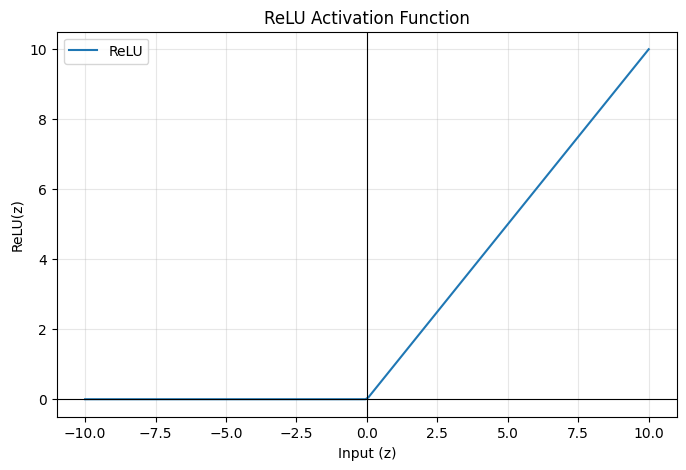

In [7]:


x = np.linspace(-10, 10, 200)
y = relu(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y, label="ReLU")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

plt.title("ReLU Activation Function")
plt.xlabel("Input (z)")
plt.ylabel("ReLU(z)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Step 5 Implementing the Sigmoid Activation Function

### Objective
Implement the Sigmoid activation function using NumPy and verify that it maps input values to a range between 0 and 1.

### 5.1 Sigmoid Activation Function

The Sigmoid function transforms an input value into a value between 0 and 1.

Its mathematical formula is:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Where:

- \(z\): Input value to the activation function
- \(e\): Euler's number, approximately 2.71828
- \(\sigma(z)\): Output of the Sigmoid function

### 5.2 How Sigmoid Works

- For positive inputs, the output approaches `1`.
- For negative inputs, the output approaches `0`.
- When the input is `0`, the output is exactly `0.5`.

### 5.3 Examples

| Input \(z\) | Sigmoid Output (approx.) |
|---:|---:|
| -3.0 | 0.0474 |
| -1.0 | 0.2689 |
| 0.0 | 0.5000 |
| 2.0 | 0.8808 |
| 3.5 | 0.9707 |

### Key Takeaway

Sigmoid converts numerical inputs into values between 0 and 1. It is commonly used in binary classification output layers to represent a predicted probability, although the output should be interpreted as a probability only when the model and its calibration support that interpretation.

## Step 5: Implement the Sigmoid activation function

In [8]:


def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Test with negative, zero, and positive values
test_values = np.array([-5.0, -1.0, 0.0, 1.0, 5.0])

sigmoid_outputs = sigmoid(test_values)

print("Input values:", test_values)
print("Sigmoid outputs:", sigmoid_outputs)

# Apply Sigmoid to the neuron's weighted sum
activated_output = sigmoid(weighted_sum)

print("Weighted sum:", weighted_sum)
print("Output after Sigmoid:", activated_output)


Input values: [-5. -1.  0.  1.  5.]
Sigmoid outputs: [0.00669285 0.26894142 0.5        0.73105858 0.99330715]
Weighted sum: 3.5000000000000004
Output after Sigmoid: 0.9706877692486436


## Step 6: Visualize the Sigmoid activation function

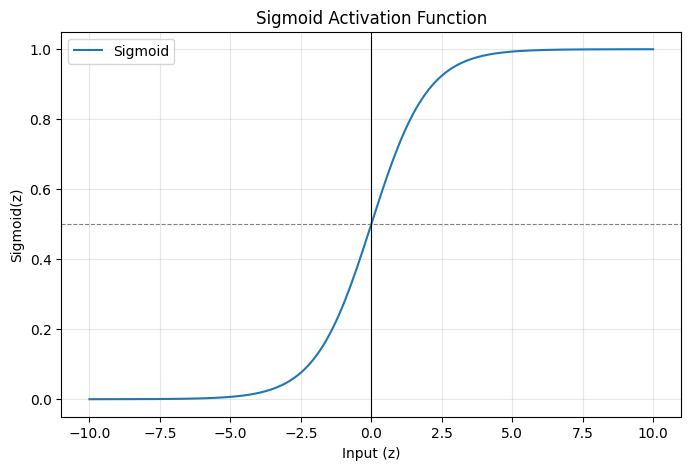

In [9]:


x = np.linspace(-10, 10, 200)
y = sigmoid(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y, label="Sigmoid")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)

plt.title("Sigmoid Activation Function")
plt.xlabel("Input (z)")
plt.ylabel("Sigmoid(z)")
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


##Step 7  Implement a Small Neural Network Layer Using NumPy

In [10]:


layer_inputs = np.array([2.0, 3.0])

layer_weights = np.array([
    [0.5, 0.8],
    [0.2, 0.4],
    [0.9, 0.1]
])

layer_biases = np.array([0.1, -0.2, 0.0])

# Calculate weighted sums
layer_z = np.dot(layer_weights, layer_inputs) + layer_biases

# Apply ReLU activation
layer_outputs = relu(layer_z)

print("Inputs:", layer_inputs)
print("Weighted sums:", layer_z)
print("Layer outputs after ReLU:", layer_outputs)
print("Number of neurons:", len(layer_outputs))


Inputs: [2. 3.]
Weighted sums: [3.5 1.4 2.1]
Layer outputs after ReLU: [3.5 1.4 2.1]
Number of neurons: 3


## Step 8: Forward propagation through two layers

In [11]:


# First layer outputs from Step 7
hidden_layer_outputs = layer_outputs

# Second layer: one output neuron
output_weights = np.array([0.4, 0.6, 0.2])
output_bias = 0.1

# Calculate output neuron's weighted sum
final_z = np.dot(hidden_layer_outputs, output_weights) + output_bias

# Apply Sigmoid activation
final_output = sigmoid(final_z)

print("Hidden layer outputs:", hidden_layer_outputs)
print("Final weighted sum:", final_z)
print("Final output after Sigmoid:", final_output)


Hidden layer outputs: [3.5 1.4 2.1]
Final weighted sum: 2.7600000000000002
Final output after Sigmoid: 0.9404756340234984


## Step 9: Compare predictions with a target value

In [12]:


target = 1.0

prediction = final_output
error = target - prediction
squared_error = (target - prediction) ** 2

print("Target:", target)
print("Prediction:", prediction)
print("Prediction error:", error)
print("Squared error:", squared_error)


Target: 1.0
Prediction: 0.9404756340234984
Prediction error: 0.05952436597650157
Squared error: 0.003543150144904498


## Step 10: Inspect the real dataset

In [13]:

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nTarget distribution:")
print(df["readmitted"].value_counts())

print("\nMissing values in top 10 columns:")
print(df.isnull().sum().sort_values(ascending=False).head(10))


Dataset shape: (101766, 50)

First 5 rows:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Target distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Missing values in top 10 columns:
max_glu_serum               96420
A1Cresult                   84748
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
dtype: int64


## Step 11: Convert '?' into actual missing values

In [14]:


df = df.replace("?", np.nan)

print("Dataset shape:", df.shape)

print("\nMissing values in top 10 columns:")
print(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("\nTotal missing values:", df.isnull().sum().sum())


Dataset shape: (101766, 50)

Missing values in top 10 columns:
weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
patient_nbr              0
dtype: int64

Total missing values: 374017


## Step 12: Calculate missing-value percentages

In [15]:


missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)

print("Top 10 columns by missing percentage:")
display(missing_summary.head(10))

print("\nColumns with more than 50% missing data:")
display(missing_summary[missing_summary["missing_percentage"] > 50])


Top 10 columns by missing percentage:


,missing_count,missing_percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
patient_nbr,0,0.00



Columns with more than 50% missing data:


,missing_count,missing_percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28


## Step 13: Analyze target classes

In [16]:


target_counts = df["readmitted"].value_counts()
target_percentages = (
    df["readmitted"].value_counts(normalize=True) * 100
).round(2)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages
})

print("Unique target classes:", df["readmitted"].nunique())
print("\nTarget class distribution:")
display(target_summary)


Unique target classes: 3

Target class distribution:


,count,percentage
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


## Step 14: Check duplicates and repeated patients

In [17]:


print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate encounter IDs:",
    df["encounter_id"].duplicated().sum()
)

print("Unique patients:", df["patient_nbr"].nunique())

patients_with_multiple_visits = (
    df["patient_nbr"].value_counts().gt(1).sum()
)

print(
    "Patients with multiple encounters:",
    patients_with_multiple_visits
)


Exact duplicate rows: 0
Duplicate encounter IDs: 0
Unique patients: 71518
Patients with multiple encounters: 16773


## Step 15: Separate target and feature columns

In [18]:


target_column = "readmitted"

identifier_columns = [
    "encounter_id",
    "patient_nbr"
]

X = df.drop(columns=identifier_columns + [target_column])
y = df[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nIdentifier columns excluded:", identifier_columns)
print("Target column:", target_column)

print("\nTarget classes:", sorted(y.unique()))
print("\nTarget missing values:", y.isnull().sum())


Feature matrix shape: (101766, 47)
Target shape: (101766,)

Identifier columns excluded: ['encounter_id', 'patient_nbr']
Target column: readmitted

Target classes: ['<30', '>30', 'NO']

Target missing values: 0


## Step 16: Inspect feature data types

In [19]:


print("Numeric columns:", X.select_dtypes(include=np.number).shape[1])
print("Non-numeric columns:", X.select_dtypes(exclude=np.number).shape[1])

print("\nFeature data types:")
display(X.dtypes.value_counts().rename_axis("data_type").to_frame("column_count"))

print("\nSample non-numeric columns:")
display(X.select_dtypes(exclude=np.number).head())


Numeric columns: 11
Non-numeric columns: 36

Feature data types:


,column_count
data_type,
object,36
int64,11



Sample non-numeric columns:


,race,gender,age,weight,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
0,Caucasian,Female,[0-10),NaN,NaN,Pediatrics-Endocrinology,250.83,NaN,NaN,NaN,...,No,No,No,No,No,No,No,No,No,No
1,Caucasian,Female,[10-20),NaN,NaN,NaN,276,250.01,255,NaN,...,No,No,Up,No,No,No,No,No,Ch,Yes
2,AfricanAmerican,Female,[20-30),NaN,NaN,NaN,648,250,V27,NaN,...,No,No,No,No,No,No,No,No,No,Yes
3,Caucasian,Male,[30-40),NaN,NaN,NaN,8,250.43,403,NaN,...,No,No,Up,No,No,No,No,No,Ch,Yes
4,Caucasian,Male,[40-50),NaN,NaN,NaN,197,157,250,NaN,...,No,No,Steady,No,No,No,No,No,Ch,Yes


## Step 17: Review important feature columns

In [20]:


columns_to_review = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

for col in columns_to_review:
    if col in X.columns:
        print(f"\n--- {col} ---")
        print("Data type:", X[col].dtype)
        print("Unique values:", X[col].nunique())
        print("Missing values:", X[col].isnull().sum())
        print("Sample values:", X[col].dropna().unique()[:10])



--- admission_type_id ---
Data type: int64
Unique values: 8
Missing values: 0
Sample values: [6 1 2 3 4 5 8 7]

--- discharge_disposition_id ---
Data type: int64
Unique values: 26
Missing values: 0
Sample values: [25  1  3  6  2  5 11  7 10  4]

--- admission_source_id ---
Data type: int64
Unique values: 17
Missing values: 0
Sample values: [ 1  7  2  4  5  6 20  3 17  8]

--- time_in_hospital ---
Data type: int64
Unique values: 14
Missing values: 0
Sample values: [ 1  3  2  4  5 13 12  9  7 10]

--- num_lab_procedures ---
Data type: int64
Unique values: 118
Missing values: 0
Sample values: [41 59 11 44 51 31 70 73 68 33]

--- num_procedures ---
Data type: int64
Unique values: 7
Missing values: 0
Sample values: [0 5 1 6 2 3 4]

--- num_medications ---
Data type: int64
Unique values: 75
Missing values: 0
Sample values: [ 1 18 13 16  8 21 12 28 17 11]

--- number_outpatient ---
Data type: int64
Unique values: 39
Missing values: 0
Sample values: [ 0  2  1  5  7  9  3  8  4 12]

--- number

## Step 18: Define initial modeling features

In [21]:


target_column = "readmitted"

identifier_columns = [
    "encounter_id",
    "patient_nbr"
]

leakage_review_columns = [
    "discharge_disposition_id"
]

excluded_columns = identifier_columns + leakage_review_columns

X = df.drop(columns=excluded_columns + [target_column])
y = df[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Excluded columns:", excluded_columns)
print("Target classes:", sorted(y.unique()))
print("Missing target values:", y.isnull().sum())


Feature matrix shape: (101766, 46)
Target shape: (101766,)
Excluded columns: ['encounter_id', 'patient_nbr', 'discharge_disposition_id']
Target classes: ['<30', '>30', 'NO']
Missing target values: 0


## Step 19: Split by patient to reduce data leakage

In [22]:


from sklearn.model_selection import GroupShuffleSplit

groups = df["patient_nbr"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("Patients shared between sets:", len(train_patients & test_patients))
print("Training proportion:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing proportion:", round(len(X_test) / len(X) * 100, 2), "%")


Training features: (81613, 46)
Testing features: (20153, 46)
Training targets: (81613,)
Testing targets: (20153,)
Patients shared between sets: 0
Training proportion: 80.2 %
Testing proportion: 19.8 %


## Step 20: Split training data into training and validation sets

In [23]:


from sklearn.model_selection import GroupShuffleSplit

train_groups = df.loc[X_train.index, "patient_nbr"]

val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

subtrain_idx, val_idx = next(
    val_splitter.split(X_train, y_train, groups=train_groups)
)

X_subtrain = X_train.iloc[subtrain_idx].copy()
X_val = X_train.iloc[val_idx].copy()

y_subtrain = y_train.iloc[subtrain_idx].copy()
y_val = y_train.iloc[val_idx].copy()

subtrain_patients = set(train_groups.iloc[subtrain_idx])
val_patients = set(train_groups.iloc[val_idx])

print("Subtraining features:", X_subtrain.shape)
print("Validation features:", X_val.shape)
print("Subtraining targets:", y_subtrain.shape)
print("Validation targets:", y_val.shape)
print("Patients shared between subtraining and validation:",
      len(subtrain_patients & val_patients))
print("Validation proportion of original training set:",
      round(len(X_val) / len(X_train) * 100, 2), "%")


Subtraining features: (69328, 46)
Validation features: (12285, 46)
Subtraining targets: (69328,)
Validation targets: (12285,)
Patients shared between subtraining and validation: 0
Validation proportion of original training set: 15.05 %


## Step 21: Build and fit the preprocessing pipeline

In [24]:


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_subtrain.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_subtrain.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit only on subtraining data
X_subtrain_processed = preprocessor.fit_transform(X_subtrain)

# Validation data is transformed using the same fitted pipeline
X_val_processed = preprocessor.transform(X_val)

print("Numeric input columns:", len(numeric_features))
print("Categorical input columns:", len(categorical_features))
print("Processed subtraining shape:", X_subtrain_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Output format:", type(X_subtrain_processed).__name__)
print("Preprocessing fitted on subtraining data only.")


Numeric input columns: 10
Categorical input columns: 36
Processed subtraining shape: (69328, 2325)
Processed validation shape: (12285, 2325)
Output format: csr_matrix
Preprocessing fitted on subtraining data only.


## Step 22: Encode target labels

In [25]:


from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_subtrain_encoded = label_encoder.fit_transform(y_subtrain)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

print("Class mapping:")

for class_name, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{class_name} -> {encoded_value}")

print("\nEncoded subtraining shape:", y_subtrain_encoded.shape)
print("Encoded validation shape:", y_val_encoded.shape)
print("Encoded test shape:", y_test_encoded.shape)
print("Number of classes:", len(label_encoder.classes_))


Class mapping:
<30 -> 0
>30 -> 1
NO -> 2

Encoded subtraining shape: (69328,)
Encoded validation shape: (12285,)
Encoded test shape: (20153,)
Number of classes: 3


## Step 23: Compare class distribution across data splits

In [26]:


def show_class_distribution(name, labels):
    counts = labels.value_counts().reindex(
        label_encoder.classes_,
        fill_value=0
    )
    percentages = (counts / len(labels) * 100).round(2)

    summary = pd.DataFrame({
        "count": counts,
        "percentage": percentages
    })

    print(f"\n{name} class distribution:")
    display(summary)

show_class_distribution("Subtraining", y_subtrain)
show_class_distribution("Validation", y_val)
show_class_distribution("Test", y_test)



Subtraining class distribution:


,count,percentage
readmitted,,
<30,7804,11.26
>30,24280,35.02
NO,37244,53.72



Validation class distribution:


,count,percentage
readmitted,,
<30,1402,11.41
>30,4277,34.81
NO,6606,53.77



Test class distribution:


,count,percentage
readmitted,,
<30,2151,10.67
>30,6988,34.67
NO,11014,54.65


## Step 24: Train a baseline neural network

In [32]:

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

# Updated neural network
model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.01,
    batch_size=256,
    learning_rate_init=0.0005,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    tol=0.0001,
    random_state=42,
    verbose=True
)

print("Training updated neural network...")

model.fit(
    X_subtrain_processed,
    y_subtrain_encoded
)

# Evaluate using the separate validation dataset
val_predictions = model.predict(X_val_processed)

val_accuracy = accuracy_score(
    y_val_encoded,
    val_predictions
)

val_macro_f1 = f1_score(
    y_val_encoded,
    val_predictions,
    average="macro"
)

print("\nTraining completed.")
print("Training iterations:", model.n_iter_)
print("Validation accuracy:", round(val_accuracy, 4))
print("Validation macro F1:", round(val_macro_f1, 4))


Training updated neural network...
Iteration 1, loss = 0.90995020
Validation score: 0.570316
Iteration 2, loss = 0.88275403
Validation score: 0.581134
Iteration 3, loss = 0.87226962
Validation score: 0.580701
Iteration 4, loss = 0.86057193
Validation score: 0.579114
Iteration 5, loss = 0.84860139
Validation score: 0.572768
Iteration 6, loss = 0.83397807
Validation score: 0.570172
Iteration 7, loss = 0.81534236
Validation score: 0.576085
Iteration 8, loss = 0.79277464
Validation score: 0.568729
Iteration 9, loss = 0.77007285
Validation score: 0.564546
Iteration 10, loss = 0.74311929
Validation score: 0.554594
Iteration 11, loss = 0.71509772
Validation score: 0.548969
Iteration 12, loss = 0.68995157
Validation score: 0.538584
Iteration 13, loss = 0.66274110
Validation score: 0.541757
Validation score did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.

Training completed.
Training iterations: 13
Validation accuracy: 0.5762
Validation macro F1: 0.3916


## Step 25: Detailed validation evaluation

In [35]:

import numpy as np
from scipy.sparse import vstack
from sklearn.utils import resample
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_train_array = np.asarray(y_subtrain_encoded)
classes, counts = np.unique(y_train_array, return_counts=True)

print("Original class counts:", dict(zip(classes, counts)))

# Partial oversampling: increase minority classes to 60% of majority size
target_count = int(counts.max() * 0.60)

X_parts = [X_subtrain_processed]
y_parts = [y_train_array]

for cls, count in zip(classes, counts):
    if count < target_count:
        class_indices = np.where(y_train_array == cls)[0]

        sampled_indices = resample(
            class_indices,
            replace=True,
            n_samples=target_count - count,
            random_state=42 + int(cls)
        )

        X_parts.append(X_subtrain_processed[sampled_indices])
        y_parts.append(y_train_array[sampled_indices])

X_partial = vstack(X_parts, format="csr")
y_partial = np.concatenate(y_parts)

# Shuffle the combined training set
rng = np.random.RandomState(42)
order = rng.permutation(len(y_partial))
X_partial = X_partial[order]
y_partial = y_partial[order]

print("Partial oversampling counts:", dict(
    zip(*np.unique(y_partial, return_counts=True))
))

model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.01,
    batch_size=256,
    learning_rate_init=0.0005,
    max_iter=100,
    early_stopping=False,
    random_state=42,
    verbose=True
)

print("\nTraining partially balanced neural network...")
model.fit(X_partial, y_partial)

val_predictions = model.predict(X_val_processed)

print("\nValidation accuracy:",
      round(accuracy_score(y_val_encoded, val_predictions), 4))
print("Validation macro F1:",
      round(f1_score(y_val_encoded, val_predictions, average="macro"), 4))

print("\nValidation Classification Report:")
print(classification_report(
    y_val_encoded,
    val_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))



Original class counts: {np.int64(0): np.int64(7804), np.int64(1): np.int64(24280), np.int64(2): np.int64(37244)}
Partial oversampling counts: {np.int64(0): np.int64(22346), np.int64(1): np.int64(24280), np.int64(2): np.int64(37244)}

Training partially balanced neural network...
Iteration 1, loss = 1.01592061
Iteration 2, loss = 0.98074810
Iteration 3, loss = 0.94913713
Iteration 4, loss = 0.90382371
Iteration 5, loss = 0.84735334
Iteration 6, loss = 0.79139890
Iteration 7, loss = 0.74431061
Iteration 8, loss = 0.70366376
Iteration 9, loss = 0.66948955
Iteration 10, loss = 0.63745934
Iteration 11, loss = 0.61267466
Iteration 12, loss = 0.58887041
Iteration 13, loss = 0.56675998
Iteration 14, loss = 0.54526044
Iteration 15, loss = 0.52903057
Iteration 16, loss = 0.51263453
Iteration 17, loss = 0.49402997
Iteration 18, loss = 0.47866783
Iteration 19, loss = 0.46765604
Iteration 20, loss = 0.45711584
Iteration 21, loss = 0.44340786
Iteration 22, loss = 0.43211111
Iteration 23, loss = 0.42

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(



Validation accuracy: 0.4795
Validation macro F1: 0.3895

Validation Classification Report:
              precision    recall  f1-score   support

         <30       0.17      0.18      0.18      1402
         >30       0.40      0.38      0.39      4277
          NO       0.60      0.61      0.60      6606

    accuracy                           0.48     12285
   macro avg       0.39      0.39      0.39     12285
weighted avg       0.48      0.48      0.48     12285



Confusion Matrix:
[[ 259  521  622]
 [ 574 1618 2085]
 [ 681 1911 4014]]


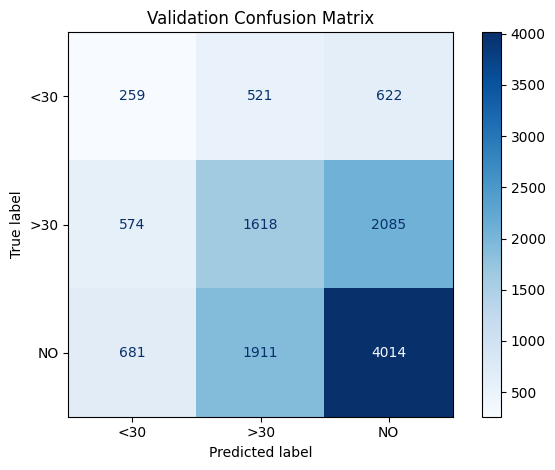

In [36]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix using validation data
cm = confusion_matrix(
    y_val_encoded,
    val_predictions
)

print("Confusion Matrix:")
print(cm)

# Visualize results
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

display.plot(cmap="Blues", values_format="d")
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()


##Step 26  Compare Neural Network Models

In [39]:

import pandas as pd
from IPython.display import display as show_table

model_comparison = pd.DataFrame([
    {
        "Model": "Baseline (64 neurons)",
        "Accuracy": 0.5274,
        "Macro F1": 0.4015
    },
    {
        "Model": "Updated (128, 64)",
        "Accuracy": 0.5762,
        "Macro F1": 0.3916
    },
    {
        "Model": "Fully balanced (128, 64)",
        "Accuracy": 0.4454,
        "Macro F1": 0.3818
    }
])

model_comparison = model_comparison.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

show_table(model_comparison)


,Model,Accuracy,Macro F1
0,Baseline (64 neurons),0.5274,0.4015
1,"Updated (128, 64)",0.5762,0.3916
2,"Fully balanced (128, 64)",0.4454,0.3818


## Step 27  Save the Best Model

In [40]:

import joblib
from sklearn.neural_network import MLPClassifier

# Recreate the baseline model
best_model = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=False,
    random_state=42,
    verbose=True
)

print("Training selected baseline model...")

best_model.fit(
    X_subtrain_processed,
    y_subtrain_encoded
)

# Save the trained model and preprocessing objects
joblib.dump(best_model, "best_neural_network.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("\nSaved successfully:")
print("- best_neural_network.pkl")
print("- preprocessor.pkl")
print("- label_encoder.pkl")


Training selected baseline model...
Iteration 1, loss = 0.90109795
Iteration 2, loss = 0.87813871
Iteration 3, loss = 0.86747143
Iteration 4, loss = 0.85702320
Iteration 5, loss = 0.84552125
Iteration 6, loss = 0.83312459
Iteration 7, loss = 0.82134417
Iteration 8, loss = 0.80697880
Iteration 9, loss = 0.79373996
Iteration 10, loss = 0.77853909
Iteration 11, loss = 0.76479470
Iteration 12, loss = 0.75040901
Iteration 13, loss = 0.73596481
Iteration 14, loss = 0.72339298
Iteration 15, loss = 0.71142695
Iteration 16, loss = 0.69810604
Iteration 17, loss = 0.68781874
Iteration 18, loss = 0.67557950
Iteration 19, loss = 0.66484975
Iteration 20, loss = 0.65508934
Iteration 21, loss = 0.64536425
Iteration 22, loss = 0.63604229
Iteration 23, loss = 0.62698958
Iteration 24, loss = 0.61931154
Iteration 25, loss = 0.61127901
Iteration 26, loss = 0.60350952
Iteration 27, loss = 0.59427562
Iteration 28, loss = 0.58910654
Iteration 29, loss = 0.58345093
Iteration 30, loss = 0.57687256

Saved succes

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
